In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

In [17]:
def extension_problem(kind, data):
    v = np.column_stack([minmax(data[:, j]) for j in range(7)])
    if kind == 'ESG':
        risk = 0.5*v[:,1]+0.5*v[:,2]
        friction = 0.4*(1-v[:,3])+0.4*(1-v[:,4])+0.2*(1-v[:,5])
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.1*(1-v[:,6])
    elif kind == '암호화폐':
        risk = 0.6*v[:,1]+0.4*v[:,5]
        friction = 0.5*(1-v[:,2])+0.5*v[:,3]
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.05*(1-v[:,4])+0.05*(1-v[:,6])
    else:
        risk = 0.4*v[:,1]+0.4*(1-v[:,3])+0.2*v[:,4]
        friction = 0.5*(1-v[:,2])+0.5*v[:,5]
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.1*(1-v[:,6])

    train, test = train_test_split(np.arange(30), test_size=0.3, random_state=42)
    labels = (cost <= np.median(cost[train])).astype(float)
    probabilities = train_classifier(np.column_stack([risk, friction]), labels, kind+' QNN', (train, test))

    basket_cost = cost.reshape(5, 6).mean(axis=1)
    problem = QuadraticProgram()
    for name in 'ABCDE': problem.binary_var(name)
    problem.minimize(linear=basket_cost)
    problem.linear_constraint({name: 1 for name in 'ABCDE'}, '==', 1, 'one_basket')

    print(kind, '바스켓 비용:', basket_cost)

    qaoa_result = run_qaoa(problem, kind+' QAOA')
    vqe_result = run_vqe(problem, kind+' VQE')  # 변수명을 결과 딕셔너리로 받음

    return {
        'risk': risk, 'friction': friction, 'cost': cost, 'basket_cost': basket_cost,
        'labels': labels, 'probabilities': probabilities, 'test': test,
        'qaoa_bits': qaoa_result["x"].copy(),
        'vqe_bits': vqe_result["x"].copy()
    }

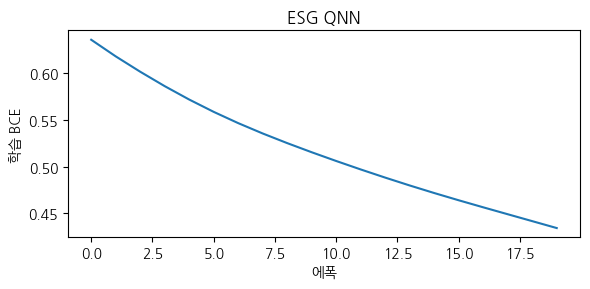

ESG 바스켓 비용: [0.32873324 0.35812116 0.35801467 0.3232508  0.3347688 ]


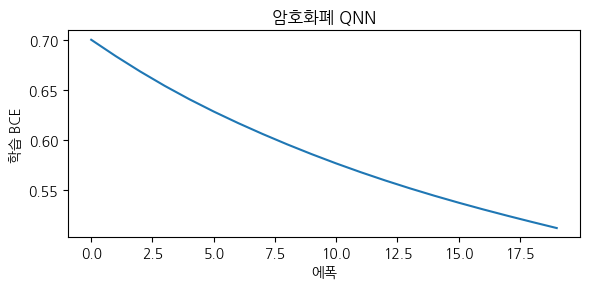

암호화폐 바스켓 비용: [0.3204954  0.33821598 0.3338914  0.33097008 0.33170217]


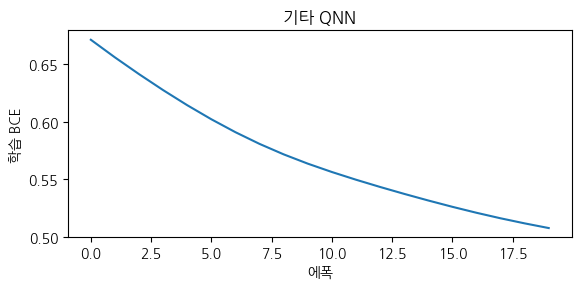

기타 바스켓 비용: [0.3708413  0.36815262 0.3604472  0.34864965 0.36203098]
ESG QAOA 선택 바스켓: ['D']


In [18]:
esg_result = extension_problem('ESG', fin_data)
crypto_result = extension_problem('암호화폐', fin_data)
default_result = extension_problem('기타', fin_data)

print("ESG QAOA 선택 바스켓:", np.array(list('ABCDE'))[esg_result['qaoa_bits'] > 0.5])